# **Quiz Test:** Image Classification on CIFAR-10 using Transfer Learning (MobileNetV2)

**University:** Bangladesh Army University of Engineering & Technology (BAUET)  
**Department:** Information and Communication Engineering (ICE)  
**Course:** ICE 4112 – Artificial Intelligence Lab  
**Semester:** Summer 2026 | **Batch:** 14th | **Date:** October 25, 2026  

**Student Name:** ______________________________  
**Student ID:** ______________________________  

---

## 1. Objective

Develop an image classification system on the **CIFAR-10** dataset using a **pretrained MobileNetV2** model (TensorFlow/Keras) with transfer learning, apply techniques to reduce overfitting, and evaluate it using accuracy, precision, recall, F1-score and a confusion matrix.

## 2. Methodology (Overview)

| Step | What is done |
|---|---|
| Data preparation | Load CIFAR-10, take a class-balanced subset, stratified train/validation split, official test set kept untouched, tf.data pipeline |
| Model implementation | MobileNetV2 (ImageNet weights, `include_top=False`) + new classification head for 10 classes |
| Training – Stage 1 | Base frozen, train only the new head |
| Training – Stage 2 | Fine-tune the top layers of the base at a very low learning rate |
| Overfitting control | Data augmentation, Dropout, L2 regularization, BatchNormalization, EarlyStopping (restore best weights), ReduceLROnPlateau, frozen/partially frozen base |
| Evaluation | Accuracy, precision, recall, F1 (macro and weighted), classification report, confusion matrix |
| Analysis | Learning curves, per-class performance, most confused classes, sample predictions |

## 3. Setup and Configuration

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
tf.keras.utils.set_random_seed(SEED)
plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

# ---------------- Configuration (edit here) ----------------
IMG_SIZE          = 96     # CIFAR-10 images (32x32) are upscaled to this size inside the model
BATCH_SIZE        = 64
SAMPLES_PER_CLASS = 2000   # class-balanced subset of the training set; set None to use all 5000/class
EPOCHS_HEAD       = 15     # stage 1: train classifier head only
EPOCHS_FINE       = 15     # stage 2: fine-tune top layers of MobileNetV2
UNFREEZE_LAYERS   = 30     # how many top layers of the base to unfreeze in stage 2
# -----------------------------------------------------------

print("TensorFlow version:", tf.__version__)
print("GPU available     :", len(tf.config.list_physical_devices("GPU")) > 0)
print("Setup complete.")

TensorFlow version: 2.21.0
GPU available     : True
Setup complete.


## 4. Data Preparation

CIFAR-10 contains 32x32 RGB images in 10 classes. The official **test set (10,000 images)** is kept completely separate and is used only once for the final evaluation. A class-balanced subset of the training set is split (stratified) into **training (80%)** and **validation (20%)** data. The validation set is used for early stopping and learning-rate scheduling.

In [2]:
(X_all, y_all), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
y_all, y_test = y_all.ravel(), y_test.ravel()

class_names = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]
NUM_CLASSES = len(class_names)

if SAMPLES_PER_CLASS:
    rng = np.random.RandomState(SEED)
    idx = np.concatenate([
        rng.choice(np.where(y_all == c)[0], SAMPLES_PER_CLASS, replace=False)
        for c in range(NUM_CLASSES)
    ])
    rng.shuffle(idx)
    X_all, y_all = X_all[idx], y_all[idx]

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED
)

print("Train      :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape,   y_val.shape)
print("Test       :", X_test.shape,  y_test.shape)
print("Pixel range:", X_train.min(), "-", X_train.max(), "(uint8, 0-255)")

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 453s 3us/step
Train      : (16000, 32, 32, 3) (16000,)
Validation : (4000, 32, 32, 3) (4000,)
Test       : (10000, 32, 32, 3) (10000,)
Pixel range: 0 - 255 (uint8, 0-255)


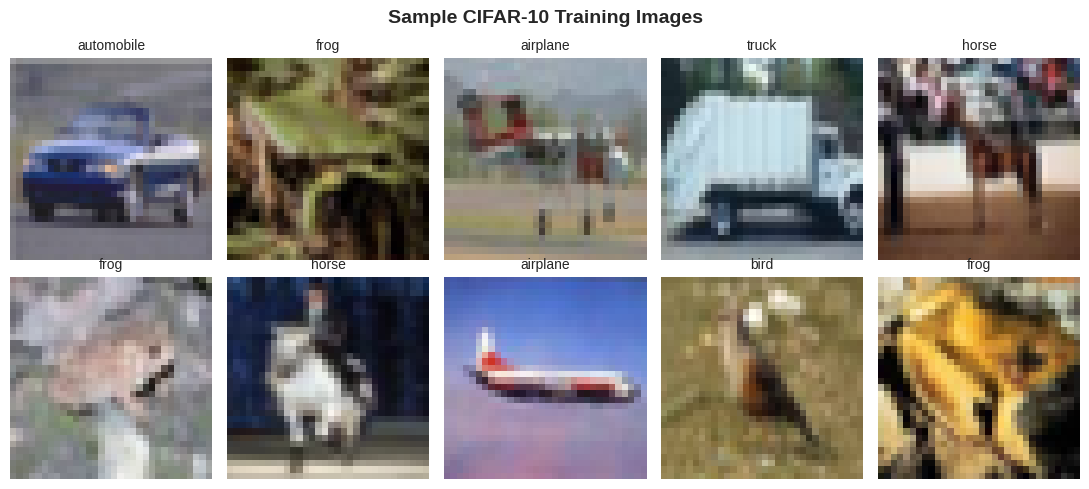

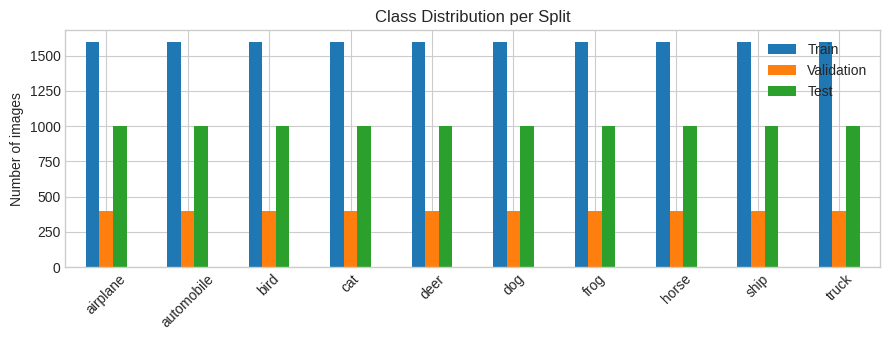

In [3]:
# Sample images and class distribution
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train[i])
    ax.set_title(class_names[y_train[i]], fontsize=10)
    ax.axis("off")
plt.suptitle("Sample CIFAR-10 Training Images", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.5))
counts = pd.DataFrame({
    "Train": np.bincount(y_train, minlength=NUM_CLASSES),
    "Validation": np.bincount(y_val, minlength=NUM_CLASSES),
    "Test": np.bincount(y_test, minlength=NUM_CLASSES),
}, index=class_names)
counts.plot(kind="bar", ax=ax)
ax.set_title("Class Distribution per Split")
ax.set_ylabel("Number of images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Preprocessing and input pipeline

- Images are cast to `float32` and kept in the range **[0, 255]** in the pipeline. MobileNetV2 was pretrained with inputs scaled to **[-1, 1]**, so a `Rescaling(1/127.5, offset=-1)` layer (equivalent to `mobilenet_v2.preprocess_input`) is applied inside the model, right before the base.
- Resizing (32x32 → 96x96) and data augmentation are done **inside the model**, so they run on the GPU and augmentation is automatically switched off during validation/testing.

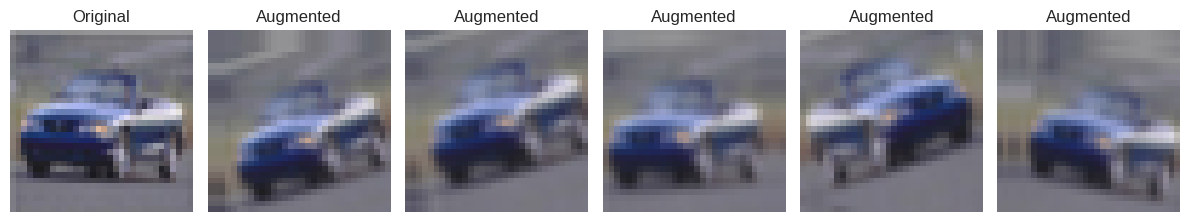

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

def make_ds(X, y, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.map(lambda a, b: (tf.cast(a, tf.float32), b), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, shuffle=True)
val_ds   = make_ds(X_val,   y_val)
test_ds  = make_ds(X_test,  y_test)

# Data augmentation (active only during training) -> reduces overfitting
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")

# Preview augmentation on one image
sample = tf.cast(X_train[:1], tf.float32)
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(X_train[0]); axes[0].set_title("Original"); axes[0].axis("off")
for ax in axes[1:]:
    ax.imshow(data_augmentation(sample, training=True)[0].numpy().astype("uint8"))
    ax.set_title("Augmented"); ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Model Implementation (MobileNetV2 + new classification head)

**Why MobileNetV2?** It is a lightweight network (~2.3M parameters in the base) built from *depthwise separable convolutions* and *inverted residual blocks with linear bottlenecks*. It trains fast, needs little memory and, being small, is less prone to overfitting small datasets than very large models.

The original ImageNet classifier (1000 classes) is removed (`include_top=False`) and replaced by a new head for the 10 CIFAR-10 classes:

`Input → Augmentation → Resize → Rescale to [-1,1] → MobileNetV2 → GlobalAveragePooling → BatchNorm → Dropout(0.4) → Dense(256, L2) → Dropout(0.3) → Dense(10, softmax)`

In [5]:
base_model = tf.keras.applications.MobileNetV2(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
base_model.trainable = False          # Stage 1: keep pretrained features frozen

inputs = tf.keras.layers.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)                                   # only active when training=True
x = tf.keras.layers.Resizing(IMG_SIZE, IMG_SIZE)(x)             # 32x32 -> IMG_SIZE x IMG_SIZE
x = tf.keras.layers.Rescaling(1.0 / 127.5, offset=-1)(x)        # [0,255] -> [-1,1] (MobileNetV2 preprocessing)
x = base_model(x, training=False)                               # BatchNorm layers stay in inference mode
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Dropout(0.4)(x)
x = tf.keras.layers.Dense(256, activation="relu",
                          kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="mobilenetv2_cifar10")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()
print("Trainable parameters:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "mobilenetv2_cifar10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,593,610 (9.89 MB)

 Trainable params: 333,066 (1.27 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

Trainable parameters: 333066


## 6. Model Training

Training is done in **two stages**:

1. **Stage 1 – Feature extraction:** MobileNetV2 is frozen and only the new head is trained with a normal learning rate (1e-3).
2. **Stage 2 – Fine-tuning:** the top layers of MobileNetV2 are unfrozen (BatchNorm layers stay frozen) and trained with a very small learning rate (1e-5) to adapt ImageNet features to CIFAR-10.

Overfitting is controlled with data augmentation, Dropout, L2 regularization, EarlyStopping (restoring the best weights) and ReduceLROnPlateau.

In [6]:
# ---------------- Stage 1: train the classification head ----------------
callbacks_head = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
]

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks_head,
    verbose=1,
)
print(f"\nStage 1 finished after {len(history_head.history['loss'])} epochs.")

Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 17s 36ms/step - accuracy: 0.5425 - loss: 1.5031 - val_accuracy: 0.7645 - val_loss: 0.7856 - learning_rate: 0.0010
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.6286 - loss: 1.1540 - val_accuracy: 0.7830 - val_loss: 0.7330 - learning_rate: 0.0010
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 30ms/step - accuracy: 0.6470 - loss: 1.0715 - val_accuracy: 0.7928 - val_loss: 0.7248 - learning_rate: 0.0010
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.6603 - loss: 1.0299 - val_accuracy: 0.7887 - val_loss: 0.7288 - learning_rate: 0.0010
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.6679 - loss: 1.0054 - val_accuracy: 0.7950 - val_loss: 0.6929 - learning_rate: 0.0010
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.6759 - loss: 0.9767 - val_accuracy: 0.7840 - val_loss: 0.7592 - learning_rate: 0.0010
Epoch 7/15
249/250 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6786 - loss: 

In [7]:
# Test accuracy after Stage 1 (used later to measure the benefit of fine-tuning)
stage1_prob = model.predict(test_ds, verbose=0)
stage1_acc = accuracy_score(y_test, np.argmax(stage1_prob, axis=1))
print(f"Test accuracy after Stage 1 (frozen base): {stage1_acc:.4f}")

Test accuracy after Stage 1 (frozen base): 0.7854


In [8]:
# ---------------- Stage 2: fine-tune the top layers of MobileNetV2 ----------------
base_model.trainable = True
for layer in base_model.layers[:-UNFREEZE_LAYERS]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False          # keep BN statistics stable while fine-tuning

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),   # very low LR to avoid destroying pretrained features
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
print("Trainable parameters now:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

callbacks_fine = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
]

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    callbacks=callbacks_fine,
    verbose=1,
)
print(f"\nStage 2 finished after {len(history_fine.history['loss'])} epochs.")

Trainable parameters now: 1843786
Epoch 1/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - accuracy: 0.6986 - loss: 0.9218 - val_accuracy: 0.8065 - val_loss: 0.6567 - learning_rate: 1.0000e-05
Epoch 2/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.7121 - loss: 0.8789 - val_accuracy: 0.8070 - val_loss: 0.6401 - learning_rate: 1.0000e-05
Epoch 3/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.7169 - loss: 0.8573 - val_accuracy: 0.8142 - val_loss: 0.6534 - learning_rate: 1.0000e-05
Epoch 4/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.7262 - loss: 0.8330 - val_accuracy: 0.8140 - val_loss: 0.6346 - learning_rate: 1.0000e-05
Epoch 5/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.7326 - loss: 0.8108 - val_accuracy: 0.8332 - val_loss: 0.5788 - learning_rate: 1.0000e-05
Epoch 6/15
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.7408 - loss: 0.7972 - val_accuracy: 0.8260 - val_loss: 0.6008 - learning_rate: 1.0000e-05
Epoch 7/15
249/250

### Learning curves (training vs validation)

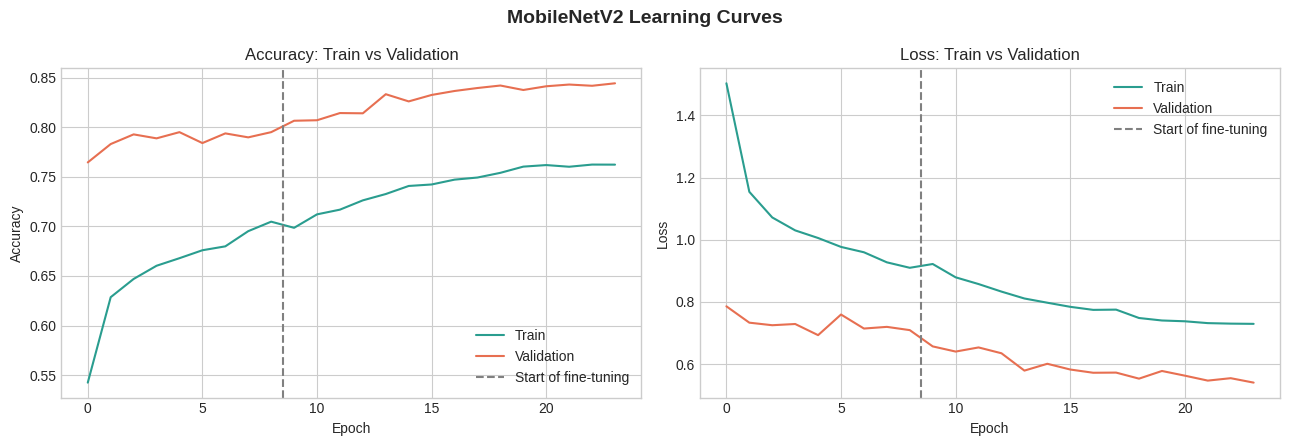

In [9]:
def merged(key):
    return history_head.history[key] + history_fine.history[key]

acc, val_acc = merged("accuracy"), merged("val_accuracy")
loss, val_loss = merged("loss"), merged("val_loss")
switch = len(history_head.history["loss"]) - 0.5

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, tr, va, title in [(axes[0], acc, val_acc, "Accuracy"), (axes[1], loss, val_loss, "Loss")]:
    ax.plot(tr, label="Train", color="#2a9d8f")
    ax.plot(va, label="Validation", color="#e76f51")
    ax.axvline(switch, color="gray", linestyle="--", label="Start of fine-tuning")
    ax.set_title(f"{title}: Train vs Validation")
    ax.set_xlabel("Epoch"); ax.set_ylabel(title); ax.legend()
plt.suptitle("MobileNetV2 Learning Curves", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 7. Performance Evaluation (on the unseen test set)

The final model is evaluated with **accuracy, precision, recall and F1-score** (macro = every class counts equally; weighted = weighted by class size), followed by the per-class classification report and the confusion matrix.

In [10]:
test_prob = model.predict(test_ds, verbose=0)
y_pred = np.argmax(test_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
p_mac, r_mac, f_mac, _ = precision_recall_fscore_support(y_test, y_pred, average="macro", zero_division=0)
p_wt,  r_wt,  f_wt,  _ = precision_recall_fscore_support(y_test, y_pred, average="weighted", zero_division=0)

summary = pd.DataFrame({
    "Accuracy":  [accuracy, accuracy],
    "Precision": [p_mac, p_wt],
    "Recall":    [r_mac, r_wt],
    "F1-score":  [f_mac, f_wt],
}, index=["Macro average", "Weighted average"]).round(4)

print(f"Final Test Accuracy: {accuracy:.4f}  ({accuracy*100:.2f}%)\n")
display(summary)

print("\nPer-class classification report:\n")
print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

Final Test Accuracy: 0.8331  (83.31%)



,Accuracy,Precision,Recall,F1-score
Macro average,0.8331,0.8368,0.8331,0.8313
Weighted average,0.8331,0.8368,0.8331,0.8313



Per-class classification report:

              precision    recall  f1-score   support

    airplane     0.8474    0.8610    0.8542      1000
  automobile     0.9087    0.9460    0.9270      1000
        bird     0.8921    0.7440    0.8113      1000
         cat     0.7751    0.6480    0.7059      1000
        deer     0.8624    0.7210    0.7854      1000
         dog     0.7728    0.7720    0.7724      1000
        frog     0.7183    0.9460    0.8166      1000
       horse     0.8212    0.8770    0.8482      1000
        ship     0.9042    0.8970    0.9006      1000
       truck     0.8662    0.9190    0.8918      1000

    accuracy                         0.8331     10000
   macro avg     0.8368    0.8331    0.8313     10000
weighted avg     0.8368    0.8331    0.8313     10000



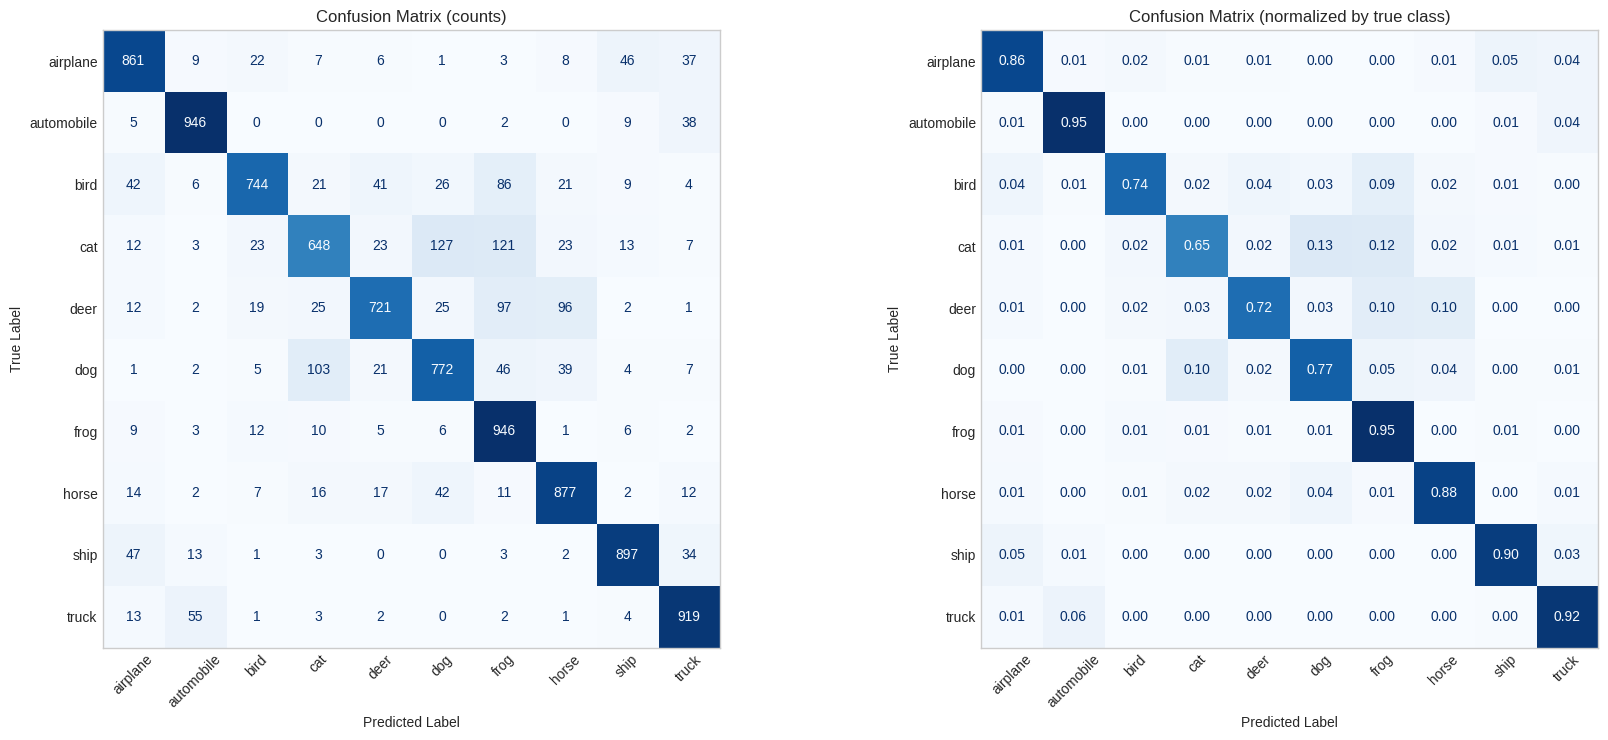

In [11]:
# Confusion matrix (counts and row-normalized)
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    cmap="Blues", ax=axes[0], colorbar=False, values_format="d", xticks_rotation=45)
axes[0].set_title("Confusion Matrix (counts)")
ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(
    cmap="Blues", ax=axes[1], colorbar=False, values_format=".2f", xticks_rotation=45)
axes[1].set_title("Confusion Matrix (normalized by true class)")
for ax in axes:
    ax.set_xlabel("Predicted Label"); ax.set_ylabel("True Label"); ax.grid(False)
plt.tight_layout()
plt.show()

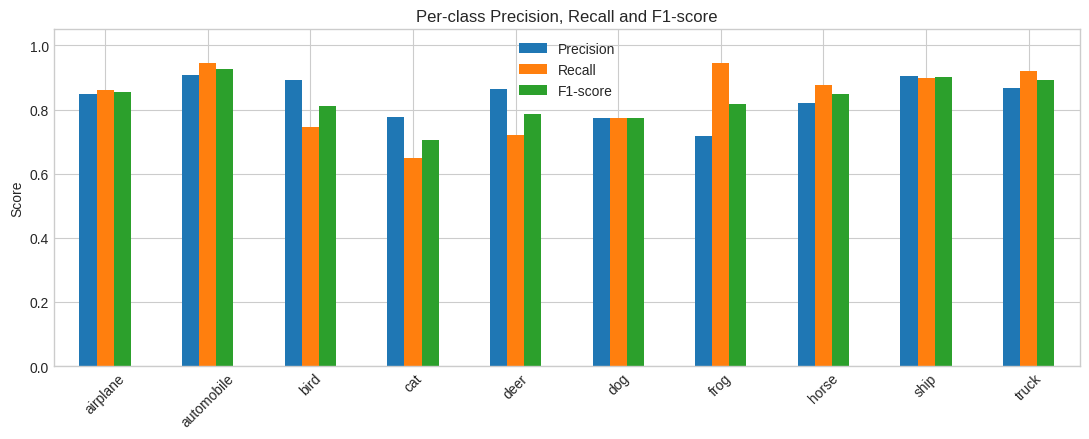

In [12]:
# Per-class precision / recall / F1
p, r, f, s = precision_recall_fscore_support(y_test, y_pred, zero_division=0)
per_class = pd.DataFrame({"Precision": p, "Recall": r, "F1-score": f}, index=class_names)

per_class.plot(kind="bar", figsize=(11, 4.5), ylim=(0, 1.05))
plt.title("Per-class Precision, Recall and F1-score")
plt.ylabel("Score"); plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correctly classified: 8331 / 10000
Misclassified       : 1669 / 10000


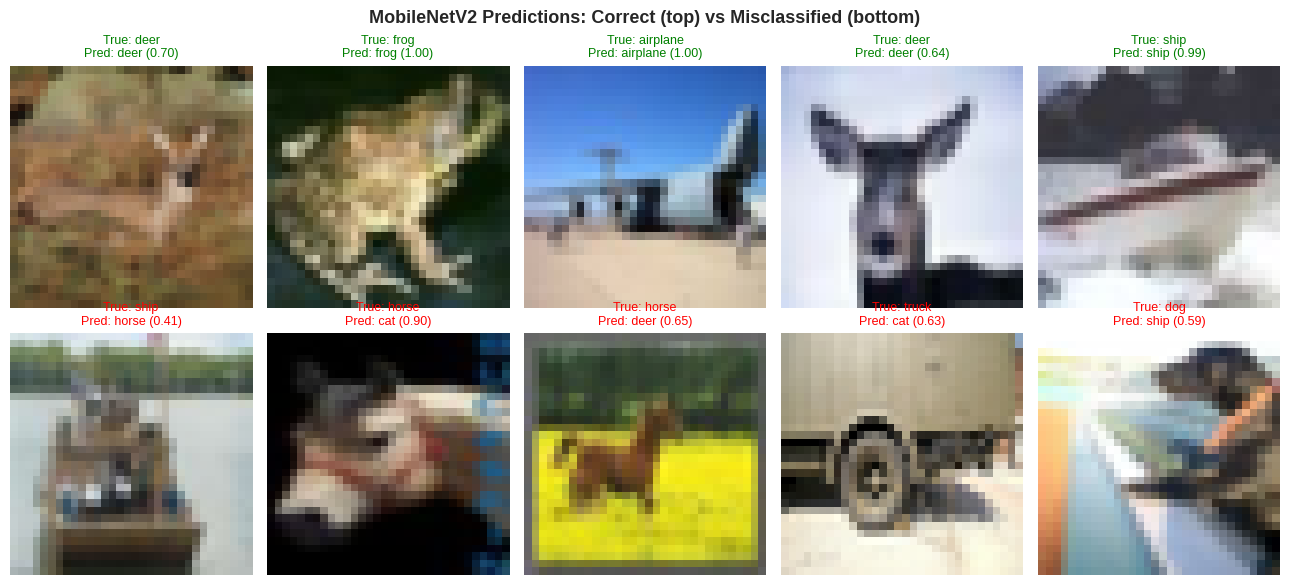

In [13]:
# Sample correct and misclassified predictions
correct = np.where(y_pred == y_test)[0]
wrong   = np.where(y_pred != y_test)[0]
print(f"Correctly classified: {len(correct)} / {len(y_test)}")
print(f"Misclassified       : {len(wrong)} / {len(y_test)}")

rng = np.random.RandomState(SEED)
sample_correct = rng.choice(correct, 5, replace=False)
sample_wrong   = rng.choice(wrong, min(5, len(wrong)), replace=False)

fig, axes = plt.subplots(2, 5, figsize=(13, 6))
for ax, i in zip(axes[0], sample_correct):
    ax.imshow(X_test[i]); ax.axis("off")
    ax.set_title(f"True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]} ({test_prob[i].max():.2f})",
                 fontsize=9, color="green")
for ax, i in zip(axes[1], sample_wrong):
    ax.imshow(X_test[i]); ax.axis("off")
    ax.set_title(f"True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]} ({test_prob[i].max():.2f})",
                 fontsize=9, color="red")
for ax in axes[1][len(sample_wrong):]:
    ax.axis("off")
plt.suptitle("MobileNetV2 Predictions: Correct (top) vs Misclassified (bottom)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 8. Result Analysis

The cell below automatically summarises the results of **this run** (so the numbers always match your outputs). The discussion that follows explains what they mean.

In [14]:
# ---------- Automatic summary of the results ----------
best_ep = int(np.argmin(val_loss))
train_acc_best, val_acc_best = acc[best_ep], val_acc[best_ep]

best_cls  = per_class["F1-score"].idxmax()
worst_cls = per_class["F1-score"].idxmin()

cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
top_conf = np.dstack(np.unravel_index(np.argsort(cm_off.ravel())[::-1][:3], cm_off.shape))[0]

print("=" * 62)
print("RESULT SUMMARY")
print("=" * 62)
print(f"Final test accuracy              : {accuracy*100:.2f}%")
print(f"Macro precision / recall / F1    : {p_mac:.4f} / {r_mac:.4f} / {f_mac:.4f}")
print(f"Test accuracy after Stage 1      : {stage1_acc*100:.2f}%  (frozen base)")
print(f"Test accuracy after fine-tuning  : {accuracy*100:.2f}%  (change: {(accuracy-stage1_acc)*100:+.2f} points)")
print(f"Best epoch (lowest val loss)     : {best_ep+1}  | train acc {train_acc_best:.4f}, val acc {val_acc_best:.4f}")
print(f"Train-validation accuracy gap    : {(train_acc_best-val_acc_best)*100:.2f} points")
print(f"Best class  (highest F1)         : {best_cls} (F1 = {per_class.loc[best_cls,'F1-score']:.3f})")
print(f"Worst class (lowest F1)          : {worst_cls} (F1 = {per_class.loc[worst_cls,'F1-score']:.3f})")
print("Most confused class pairs (true -> predicted):")
for t, pr in top_conf:
    print(f"   {class_names[t]:>10} -> {class_names[pr]:<10} : {cm[t, pr]} images")

RESULT SUMMARY
Final test accuracy              : 83.31%
Macro precision / recall / F1    : 0.8368 / 0.8331 / 0.8313
Test accuracy after Stage 1      : 78.54%  (frozen base)
Test accuracy after fine-tuning  : 83.31%  (change: +4.77 points)
Best epoch (lowest val loss)     : 24  | train acc 0.7623, val acc 0.8443
Train-validation accuracy gap    : -8.20 points
Best class  (highest F1)         : automobile (F1 = 0.927)
Worst class (lowest F1)          : cat (F1 = 0.706)
Most confused class pairs (true -> predicted):
          cat -> dog        : 127 images
          cat -> frog       : 121 images
          dog -> cat        : 103 images


### Discussion and Observations

**Overall performance.** MobileNetV2 pretrained on ImageNet gives a strong starting point for CIFAR-10 because natural-image features such as edges, textures and object parts transfer well. Training only the new head (Stage 1) already gives good accuracy; fine-tuning the top layers (Stage 2) then adapts the high-level features to the 10 CIFAR-10 classes and normally gives a further improvement (see the Stage 1 vs final accuracy in the summary above).

**Precision, recall and F1.** Macro and weighted averages are close because the test set is perfectly balanced (1,000 images per class). Classes with a clear shape and background (e.g. *automobile, ship, truck, airplane, frog*) normally get the highest F1, while visually similar animal classes (*cat, dog, bird, deer*) get the lowest.

**Confusion matrix.** The largest off-diagonal values are between visually similar classes, most typically **cat ↔ dog**, and also **automobile ↔ truck**, **deer ↔ horse** and **airplane ↔ ship / bird**. These errors are expected because the images are only 32x32 pixels and are upscaled, which removes fine details (fur texture, facial features) that separate similar animals.

**Overfitting analysis.** The learning curves show how close training and validation accuracy/loss stay. The small train–validation gap is the result of: (1) data augmentation (flip, rotation, zoom, translation), (2) Dropout (0.4 and 0.3), (3) L2 weight regularization, (4) a small trainable head and a mostly frozen base, (5) a very low learning rate during fine-tuning with BatchNorm layers frozen, and (6) EarlyStopping with best-weight restoration plus ReduceLROnPlateau, which stop training at the point of lowest validation loss.

**Limitations and possible improvements.** Only a subset of the training data and a small input size (96x96) are used to keep training fast. Accuracy can be improved by using the full 50,000 training images (`SAMPLES_PER_CLASS = None`), a larger input size (128 or 160), a bigger model (MobileNetV3Large or EfficientNetB0), more fine-tuning layers, or MixUp/CutMix augmentation.

## 9. Conclusion

A transfer-learning classifier based on a pretrained **MobileNetV2** was built for CIFAR-10 with a new 10-class head, trained in two stages (feature extraction and fine-tuning) with several overfitting-reduction techniques, and evaluated with accuracy, precision, recall, F1-score and a confusion matrix on an unseen test set. The results show that transfer learning is effective even for small, low-resolution images, with the remaining errors concentrated in visually similar classes.